In [3]:
pacman::p_load(dplyr,ggplot2,lubridate,ggridges,ggmap,patchwork,ggnewscale,
               RColorBrewer,trend)

In [2]:
proro_abundance=read.csv("~/data/arianna/2025-provincetown-metaT/pull_abundances_prorocentrales/salmon_mapping_all_seqs_Prorocentrales.csv")

In [4]:
species_codes = read.csv(file.path("../data","ccb_count","CC_plankton_200_2021_metadata_species.csv")) %>%
    dplyr::mutate(SPEC_CODE_MUT=dplyr::case_when(!is.na(as.numeric(as.character(SPEC_CODE))) ~ 
                                                 as.character(as.numeric(as.character(SPEC_CODE))),
                                                 TRUE ~ as.character(SPEC_CODE)))

plankton_metadata = read.csv("../data/ccb_count/CC_plankton_200_2021_metadata_species.csv")
plankton_counts = read.csv("../data/ccb_count/cc_plankton_2020_202307.csv")
merged_pkton = plankton_counts %>% dplyr::left_join(plankton_metadata)

paired_data = read.csv(file.path("../data","ccb_count","cc_plankton_2000_2021.csv")) %>%
    dplyr::mutate(SPEC_CODE = as.character(SPEC_CODE)) %>%
    dplyr::mutate(SPEC_CODE_MUT=dplyr::case_when(!is.na(as.numeric(as.character(SPEC_CODE))) ~ 
                                                 as.character(as.numeric(as.character(SPEC_CODE))),
                                                 TRUE ~ as.character(SPEC_CODE)))%>%
    dplyr::left_join(species_codes,by=c("SPEC_CODE_MUT")) %>%
    dplyr::bind_rows(merged_pkton) %>%
    dplyr::mutate(Date=as.Date(STAT_ARRIV,format='%d-%b-%Y %H:%M:%S')) %>%
    dplyr::filter(!(trimws(GROUP_ID) %in% c("COPEPOD",
                                             "OTHER (ZOO)",
                                             "BARNACLE"))) 

Warning message:
“There were 2 warnings in `dplyr::mutate()`.
The first warning was:
ℹ In argument: `SPEC_CODE_MUT = dplyr::case_when(...)`.
Caused by warning:
! NAs introduced by coercion
ℹ Run `dplyr::last_dplyr_warnings()` to see the 1 remaining warning.”
Joining with `by = join_by(SPEC_CODE)`
Warning message:
“There were 2 warnings in `dplyr::mutate()`.
The first warning was:
ℹ In argument: `SPEC_CODE_MUT = dplyr::case_when(...)`.
Caused by warning:
! NAs introduced by coercion
ℹ Run `dplyr::last_dplyr_warnings()` to see the 1 remaining warning.”


`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  and UNIT_CODE.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, and DESCR.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, and
  DESCR.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, and GROUP_ID.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR))` for
  per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by regime, DESCR, and GROUP_ID.
ℹ Output is grouped by regime and DESCR.
ℹ Use `summarise(.groups = "drop_last")` to silence this

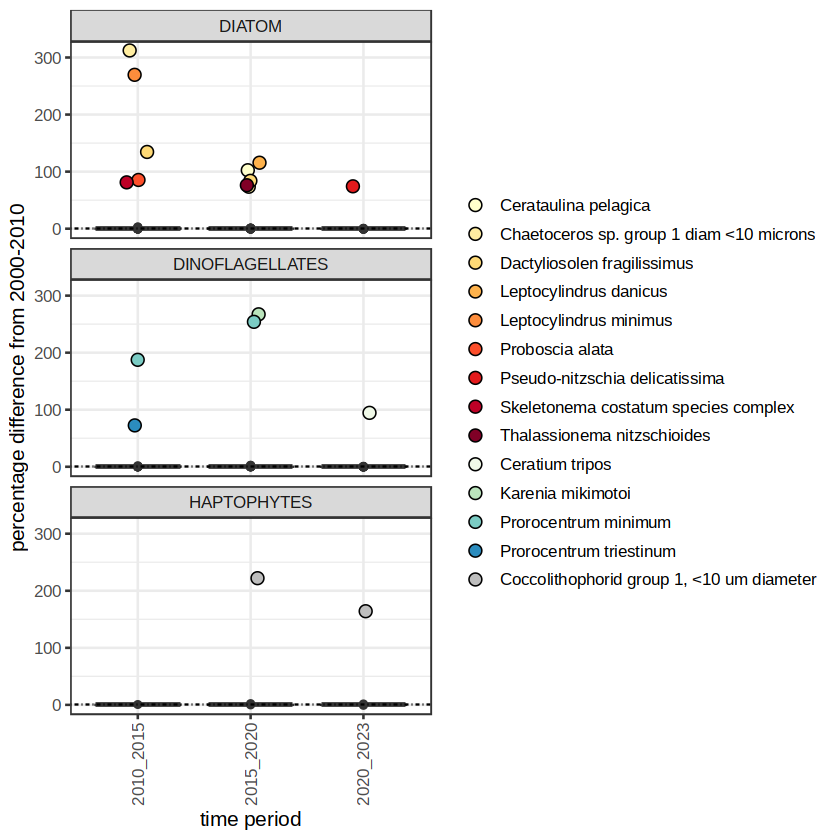

In [5]:
infill_dates = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES")) %>%
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date"),names_from="DESCR",values_from="Group_Ct")

infill_dates[is.na(infill_dates)]=0

group_connect = paired_data %>% dplyr::select(GROUP_ID,DESCR) %>%
    dplyr::mutate(DESCR=trimws(DESCR)) %>%
    dplyr::distinct() %>% dplyr::filter(!is.na(GROUP_ID) & !is.na(DESCR))

for_plotting = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::mutate(GROUP_ID = case_when(grepl("DIATOM",GROUP_ID)~"DIATOM",
                                      TRUE~GROUP_ID)) %>%
    dplyr::mutate(Year = year(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                 Month = month(as.Date(Date,format='%d-%b-%Y %H:%M:%S'))) %>%
    dplyr::mutate(regime = case_when(Year > 2020 ~ "2020_2023",
                                     Year > 2015 ~ "2015_2020",
                                     Year > 2010 ~ "2010_2015",
                                    TRUE ~"early")) %>%
    dplyr::group_by(regime,DESCR,GROUP_ID) %>% dplyr::summarize(meanCt = mean(Group_Ct)) %>%
    tidyr::pivot_wider(id_cols=c("DESCR","GROUP_ID"),names_from="regime",
                       values_from="meanCt")%>%
    tidyr::pivot_longer(cols=!(starts_with("GROUP_ID")|starts_with("DESCR")|starts_with("early")),
                       names_to="regime",
                       values_to="value") %>%
    dplyr::mutate(labeled_pts = case_when(((value)-(early))/(early+0.01)> 0.7~DESCR,
                                          TRUE~NA))

seasonal_shifts = ggplot(for_plotting)+
    geom_boxplot(aes(x=regime,y=((value)-(early))/(early+0.01),group=paste0(GROUP_ID,regime)))+new_scale_fill() + 
    geom_jitter(data=for_plotting %>% dplyr::filter(!is.na(labeled_pts)) %>%
               dplyr::arrange(GROUP_ID) %>% 
               dplyr::mutate(labeled_pts=factor(labeled_pts,levels=(for_plotting %>% 
                                                dplyr::distinct(labeled_pts,.keep_all=TRUE) %>%
                                                dplyr::filter(!is.na(labeled_pts)) %>%
               dplyr::arrange(GROUP_ID))$labeled_pts)),
               aes(x=regime,y=((value)-(early))/(early+0.01)*100,group=paste0(regime,GROUP_ID),
                   fill=labeled_pts), na.rm=TRUE,pch=21,size=3,width=0.1,height=0)+ 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + facet_wrap(~GROUP_ID,nrow=3) + 
    geom_hline(aes(yintercept=0.75),linetype="dotdash") + theme_bw(base_size=12) + 
    ylab("percentage difference from 2000-2010")+ 
    scale_fill_manual(values=c(brewer.pal(9, "YlOrRd"),
                               brewer.pal(4,"GnBu"),"gray"),name="") + 
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + xlab("time period")

seasonal_shifts

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type and Date.
ℹ Output is grouped by type.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(type, Date))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


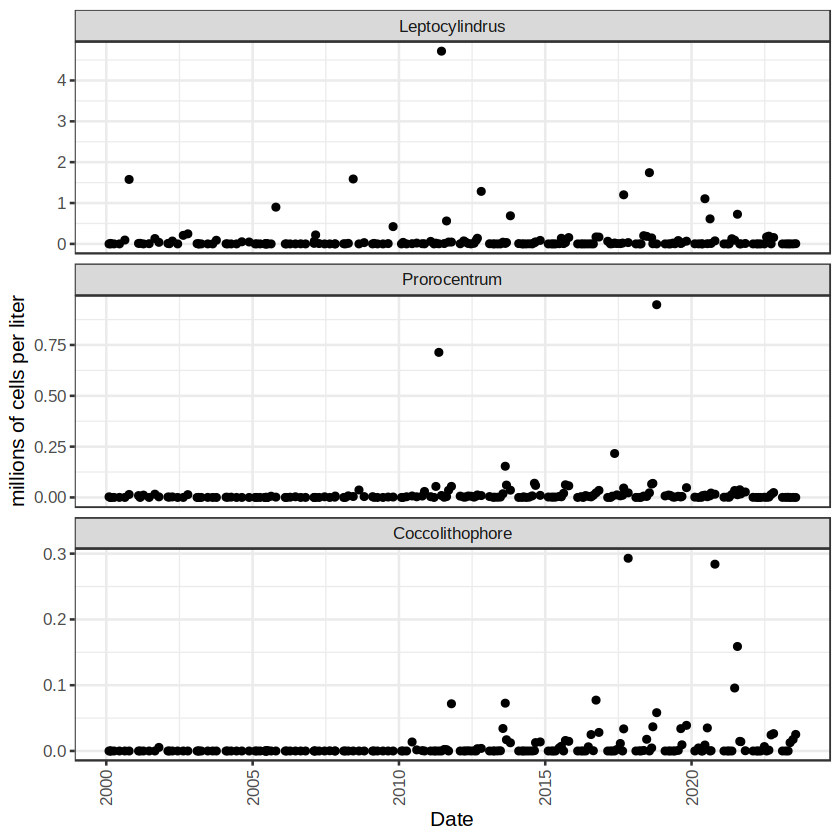

In [6]:
for_plotting = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus")) %>%
    dplyr::group_by(type,Date) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore")))) + 
    geom_point(aes(x=Date,y=Group_Ct)) + 
    theme_bw(base_size=12) + facet_wrap(~type,nrow=3,scales="free_y") +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends

In [7]:
for_prob_test = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 TRUE~DESCR)) %>%
    dplyr::group_by(type,Date) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

all_stats = data.frame()
for (curr_group in unique(for_prob_test$type)) {
    frame_for_test = for_prob_test %>% dplyr::filter(type==curr_group) %>%
        dplyr::arrange(Date)
    stats_test = mk.test(frame_for_test$Group_Ct)
    curr_fr = data.frame(statistic = stats_test$statistic,
               organism = curr_group,
               p_value = stats_test$p.value,
               total_abundance = sum(frame_for_test$Group_Ct),
               avg_abundance = mean(frame_for_test$Group_Ct))
    all_stats = all_stats %>% dplyr::bind_rows(curr_fr)
    print(curr_group)
    print(mk.test(frame_for_test$Group_Ct))
               
}

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type and Date.
ℹ Output is grouped by type.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(type, Date))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.


[1] "Acanthoica spp."

	Mann-Kendall trend test

data:  frame_for_test$Group_Ct
z = 1.0729, n = 190, p-value = 0.2833
alternative hypothesis: true S is not equal to 0
sample estimates:
           S         varS          tau 
1.670000e+02 2.393967e+04 6.418789e-02 

[1] "Achnanthes spp."

	Mann-Kendall trend test

data:  frame_for_test$Group_Ct
z = -1.1304, n = 190, p-value = 0.2583
alternative hypothesis: true S is not equal to 0
sample estimates:
            S          varS           tau 
-1.250000e+02  1.203300e+04 -6.785571e-02 

[1] "Actinoptychus senarius"

	Mann-Kendall trend test

data:  frame_for_test$Group_Ct
z = -1.3127, n = 190, p-value = 0.1893
alternative hypothesis: true S is not equal to 0
sample estimates:
            S          varS           tau 
-1.450000e+02  1.203300e+04 -7.871262e-02 

[1] "Akashiwo sanguinea"

	Mann-Kendall trend test

data:  frame_for_test$Group_Ct
z = 0.76576, n = 190, p-value = 0.4438
alternative hypothesis: true S is not equal to 0
sample est

In [8]:
stats_test$p.value

[1] 0.01476856

In [9]:
all_stats %>% dplyr::arrange(desc(statistic))

,statistic,organism,p_value,total_abundance,avg_abundance
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>
z...1,7.616620,Karenia mikimotoi,2.604046e-14,1.251416989,6.586405e-03
z...2,6.582278,Ceratium furca,4.632928e-11,0.428071617,2.253009e-03
z...3,6.513734,Pseudo-nitzschia delicatissima,7.330531e-11,0.433316918,2.280615e-03
z...4,6.386780,Coccolithophore,1.694146e-10,1.723050155,9.068685e-03
z...5,5.974759,Pennate diatom sp. group 1 <10 microns length,2.304308e-09,0.633716357,3.335349e-03
z...6,5.952313,"Protoperidinium sp. group 2 31-75 microns width, 41-80 microns length",2.643798e-09,0.438029757,2.305420e-03
z...7,4.710111,Prorocentrum,2.475814e-06,3.617651977,1.904027e-02
z...8,4.647406,Scrippsiella trochoidea,3.361358e-06,0.343793743,1.809441e-03
z...9,4.507323,Chaetoceros sp. group 1 diam <10 microns,6.565061e-06,2.129242000,1.120654e-02


In [9]:
all_stats %>% dplyr::arrange(desc(statistic)) %>% 
    dplyr::mutate(adjusted_p = p.adjust(p_value, method = "bonferroni")) %>%
    dplyr::mutate(significant = case_when(adjusted_p < 0.05 ~ "significant",
                                          TRUE ~ "not significant")) %>%
    dplyr::arrange(desc(significant),desc(avg_abundance))

,statistic,organism,p_value,total_abundance,avg_abundance,adjusted_p,significant
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
z...1,4.7101114,Prorocentrum,2.475814e-06,3.617651977,1.904027e-02,3.787995e-04,significant
z...2,4.5073231,Chaetoceros sp. group 1 diam <10 microns,6.565061e-06,2.129242000,1.120654e-02,1.004454e-03,significant
z...3,6.3867804,Coccolithophore,1.694146e-10,1.723050155,9.068685e-03,2.592044e-08,significant
z...4,-3.7142126,Chaetoceros contortus,2.038374e-04,1.284339277,6.759680e-03,3.118712e-02,significant
z...5,7.6166199,Karenia mikimotoi,2.604046e-14,1.251416989,6.586405e-03,3.984191e-12,significant
z...6,-4.7138549,"Gymnodinium sp. group 2 21-40 microns width, 21-50 microns length",2.430737e-06,1.047537178,5.513354e-03,3.719028e-04,significant
z...7,-3.7045809,Chaetoceros debilis,2.117405e-04,0.658178802,3.464099e-03,3.239630e-02,significant
z...8,5.9747589,Pennate diatom sp. group 1 <10 microns length,2.304308e-09,0.633716357,3.335349e-03,3.525591e-07,significant
z...9,4.3120723,Heterocapsa triquetra,1.617315e-05,0.619496841,3.260510e-03,2.474492e-03,significant


In [32]:
all_stats %>% dplyr::arrange(desc(statistic)) %>% 
    dplyr::mutate(adjusted_p = p.adjust(p_value, method = "bonferroni")) %>%
    dplyr::mutate(significant = case_when(adjusted_p < 0.05 ~ "significant",
                                          TRUE ~ "not significant")) %>%
    dplyr::arrange(adjusted_p) %>% dplyr::filter(statistic>0) %>% dplyr::filter(significant=="significant")

,statistic,organism,p_value,total_abundance,avg_abundance,adjusted_p,significant
,<dbl>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
z...1,7.616620,Karenia mikimotoi,2.604046e-14,1.251416989,6.586405e-03,3.984191e-12,significant
z...2,6.582278,Ceratium furca,4.632928e-11,0.428071617,2.253009e-03,7.088380e-09,significant
z...3,6.513734,Pseudo-nitzschia delicatissima,7.330531e-11,0.433316918,2.280615e-03,1.121571e-08,significant
z...4,6.386780,Coccolithophore,1.694146e-10,1.723050155,9.068685e-03,2.592044e-08,significant
z...5,5.974759,Pennate diatom sp. group 1 <10 microns length,2.304308e-09,0.633716357,3.335349e-03,3.525591e-07,significant
z...6,5.952313,"Protoperidinium sp. group 2 31-75 microns width, 41-80 microns length",2.643798e-09,0.438029757,2.305420e-03,4.045011e-07,significant
z...7,4.710111,Prorocentrum,2.475814e-06,3.617651977,1.904027e-02,3.787995e-04,significant
z...8,4.647406,Scrippsiella trochoidea,3.361358e-06,0.343793743,1.809441e-03,5.142878e-04,significant
z...9,4.507323,Chaetoceros sp. group 1 diam <10 microns,6.565061e-06,2.129242000,1.120654e-02,1.004454e-03,significant


Saving 7 x 7 in image


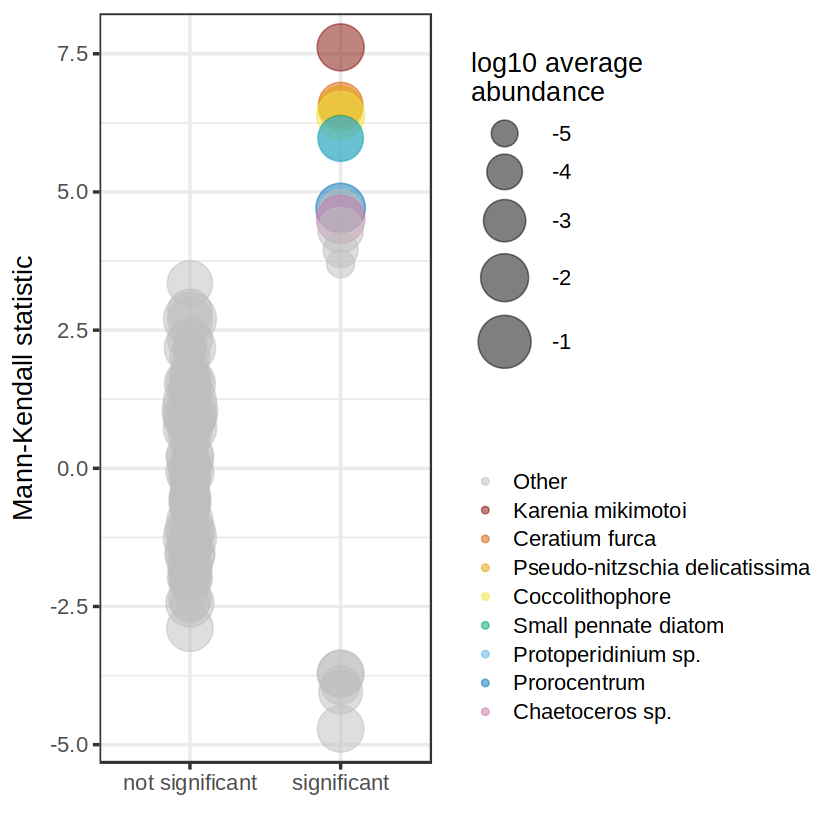

In [41]:
#Scrippsiella trochoidea	3.361358e-06	0.343793743	1.809441e-03	5.142878e-04	significant
#z...10	4.507323	Chaetoceros sp. group 1 diam <10 microns                             	6.565061e-06	2.129242000	1.120654e-02	1.004454e-03	significant    
#z...11	4.312072	Heterocapsa triquetra	1.617315e-05	0.619496841	3.260510e-03	2.474492e-03	significant
#z...12	-4.047152	Stephanopyxis turris	5.184465e-05	0.328284223	1.727812e-03	7.932231e-03	significant
#z...13	3.950567	Gonyaulax spinifera	7.796635e-05	0.015613988	8.217888e-05	1.192885e-02	significant
#z...14	-3.921249	Amphidinium spp.	8.809117e-05	0.058412672	3.074351e-04	1.347795e-02	significant
#z...15	-3.714213	Chaetoceros contortus	2.038374e-04	1.284339277	6.759680e-03	3.118712e-02	significant
#z...16	-3.704581	Chaetoceros debilis	2.117405e-04	0.658178802	3.464099e-03	3.239630e-02	significant
#z...17	3.700277	Ceratium minutum	2.153646e-

ggplot(all_stats %>% dplyr::arrange(desc(statistic)) %>% 
    dplyr::mutate(adjusted_p = p.adjust(p_value, method = "bonferroni")) %>%
    dplyr::mutate(significant = case_when(adjusted_p < 0.05 ~ "significant",
                                          TRUE ~ "not significant")) %>%
    dplyr::mutate(label = case_when(adjusted_p<0.05 ~ organism,
                                    TRUE ~ ""))%>%
    dplyr::mutate(organism=case_when(organism=="Pennate diatom sp. group 1 <10 microns length"~"Small pennate diatom",
                                     organism=="Protoperidinium sp. group 2 31-75 microns width, 41-80 microns length"~"Protoperidinium sp.",
                                     organism=="Chaetoceros sp. group 1 diam <10 microns"~"Chaetoceros sp.",
                                     TRUE~organism)) %>%
    dplyr::mutate(label_proro_cocco = case_when(organism%in%c("Coccolithophore","Prorocentrum",
                                                              "Karenia mikimotoi","Ceratium furca",
                                                              "Pseudo-nitzschia delicatissima","Small pennate diatom",
                                                              "Protoperidinium sp.","Chaetoceros sp.") ~ organism,
                                    TRUE ~ "Other")))+
    geom_point(aes(x=significant, y=statistic, color=label_proro_cocco,
                   size=log10(avg_abundance)),alpha=0.5)+
    scale_color_manual(breaks=c("Other","Karenia mikimotoi",
                                "Ceratium furca","Pseudo-nitzschia delicatissima",
                                "Coccolithophore","Small pennate diatom",
                                "Protoperidinium sp.","Prorocentrum","Chaetoceros sp."),
                       values=c("gray","#800A01","#D55E00","#E69F00","#F0E442","#009E73","#56B4E9","#0072B2",
                                "#CC79A7"),
                       name="") + 
    theme_bw(base_size=16)+scale_size(range = c(1,15),name="log10 average\nabundance") + 
    xlab("") + ylab("Mann-Kendall statistic")
ggsave("../figures/mann_kendall_tests.pdf")

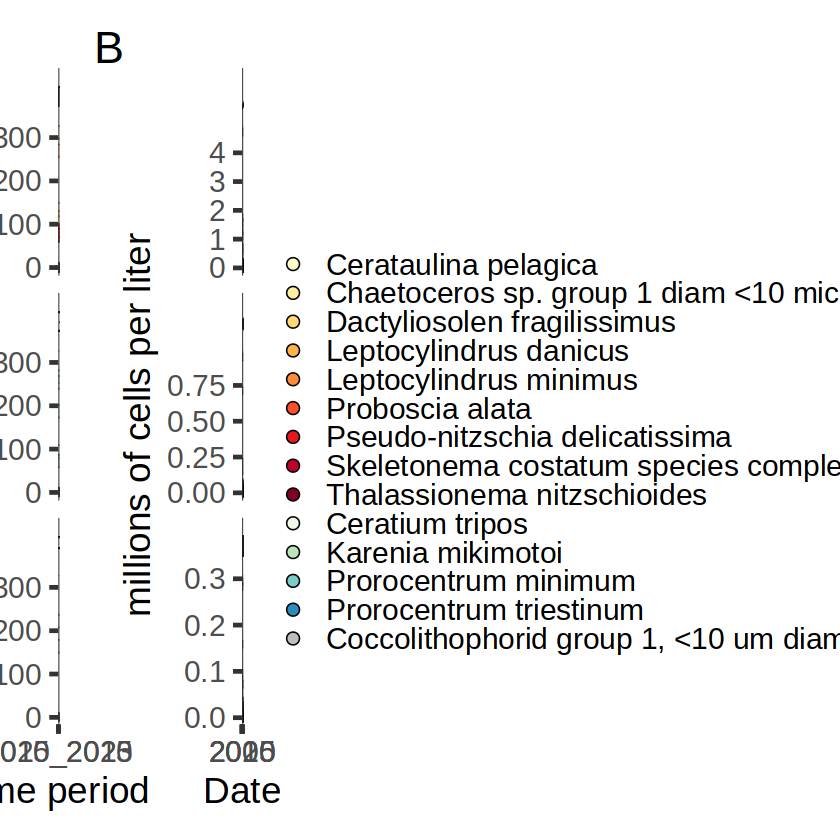

In [11]:
(seasonal_shifts+theme_bw(base_size=22)|main_grp_trends+theme_bw(base_size=22))+ 
    plot_layout(guides = "collect") & plot_annotation(tag_levels = 'A')
ggsave("../figures/trends_groups_post_2010.pdf",width=15,height=10,units="in")

In [12]:
## read in nutrient data
nutrient_data = read.csv(file.path("../data/ccb_nutrient/CC_wet_chemistry_2022_2023.csv")) %>%
    dplyr::bind_rows(read.csv(file.path("../data/ccb_nutrient/CC_wet_chemistry_2000_2021.csv")))

In [13]:
processed_df = nutrient_data %>% 
    dplyr::filter(DEPTH<5)%>%dplyr::filter(STAT_ID%in%c("F01","F02","F29"))%>%
    dplyr::filter(PARAM_CODE%in% c("NO2","NO3","NO3+NO2","CHLA","PO4","SIO4"))%>%
    dplyr::mutate(Category=case_when(PARAM_CODE %in% c("NO2","NO3","NO3+NO2")~"Nitrogen",
                                     PARAM_CODE %in% c("CHLA")~"Chlorophyll",
                                     TRUE~"Phosphorus")) %>%
    dplyr::mutate(Year = year(as.Date(STAT_ARRIV,format='%d-%b-%Y %H:%M:%S')),
                  Date=as.Date(STAT_ARRIV,format='%d-%b-%Y %H:%M:%S'))

In [9]:
unique(paired_data$DESCR)

[1] "Dictyocha speculum"                                                   
  [2] "Corethron criophilum"                                                 
  [3] "Skeletonema costatum species complex"                                 
  [4] "Thalassiosira nordenskioeldii"                                        
  [5] "Thalassiosira sp. group 3 10-20 microns length"                       
  [6] "Chaetoceros sp. group 1 diam <10 microns"                             
  [7] "Rhizosolenia setigera"                                                
  [8] "Guinardia delicatula"                                                 
  [9] "Centric diatom sp. group 1 diam <10 microns"                          
 [10] "Thalassionema nitzschioides"                                          
 [11] "Pleurosigma spp."                                                     
 [12] "Pennate diatom sp. group 2 10-30 microns length"                      
 [13] "Pennate diatom sp. group 3 31-60 microns length"                      
 [14] "Pyramimonas sp. group 1 10-20 microns length"                         
 [15] "Prorocentrum micans"                                                  
 [16] "Gymnodinium sp. group 1 5-20 microns width, 10-20 microns length"     
 [17] "Gymnodinium sp. group 2 21-40 microns width, 21-50 microns length"    
 [18] "Gyrodinium spirale"                                                   
 [19] "Cryptomonas sp. group 1 length <10 microns"                           
 [20] "Cryptomonas sp. group 2 length >10 microns"                           
 [21] "Unid. micro-phytoflag sp. group 1 length <10 microns"                 
 [22] "Unid. micro-phytoflag sp. group 2 length >10 microns"                 
 [23] "Ebria tripartita"                                                     
 [24] "Chaetoceros sp. group 2 diam 10-30 microns"                           
 [25] "Cylindrotheca closterium"                                             
 [26] "Eutreptia/Eutreptiella spp."                                          
 [27] "Gyrodinium sp. group 1 5-20 microns width, 10-20 microns length"      
 [28] "Heterocapsa rotundata"                                                
 [29] "Protoperidinium bipes"                                                
 [30] "Leptocylindrus minimus"                                               
 [31] "Thalassiosira rotula"                                                 
 [32] "Chaetoceros debilis"                                                  
 [33] "Choanoflagellate"                                                     
 [34] "Chaetoceros decipiens"                                                
 [35] "Chaetoceros socialis"                                                 
 [36] "Protoperidinium sp. group 1 10-30 microns width, 10-40 microns length"
 [37] "Thalassiosira anguste-lineata"                                        
 [38] "Thalassiosira sp. group 4 20-30 microns length"                       
 [39] "Detonula confervacea"                                                 
 [40] "Chaetoceros didymus"                                                  
 [41] "Stephanopyxis turris"                                                 
 [42] "Chaetoceros diadema"                                                  
 [43] "Asterionellopsis glacialis"                                           
 [44] "Phaeocystis pouchetii"                                                
 [45] "Paulinella ovalis"                                                    
 [46] "Prorocentrum minimum"                                                 
 [47] "Dinophysis norvegica"                                                 
 [48] "Gyrodinium sp. group 2 21-40 microns width, 21-50 microns length"     
 [49] "Protoperidinium brevipes"                                             
 [50] "Ceratium fusus"                                                       
 [51] "Calycomonas wulffii"                                                  
 [52] "Ceratium lineatum

In [ ]:
infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales")) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Cryptomonadales",
                                            "Thalassiosirales",
                                            "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y",ncol=1) +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
ggsave("../figures/abundances_w_phosphate.pdf")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type, Date, and STAT_ID.
ℹ Output i

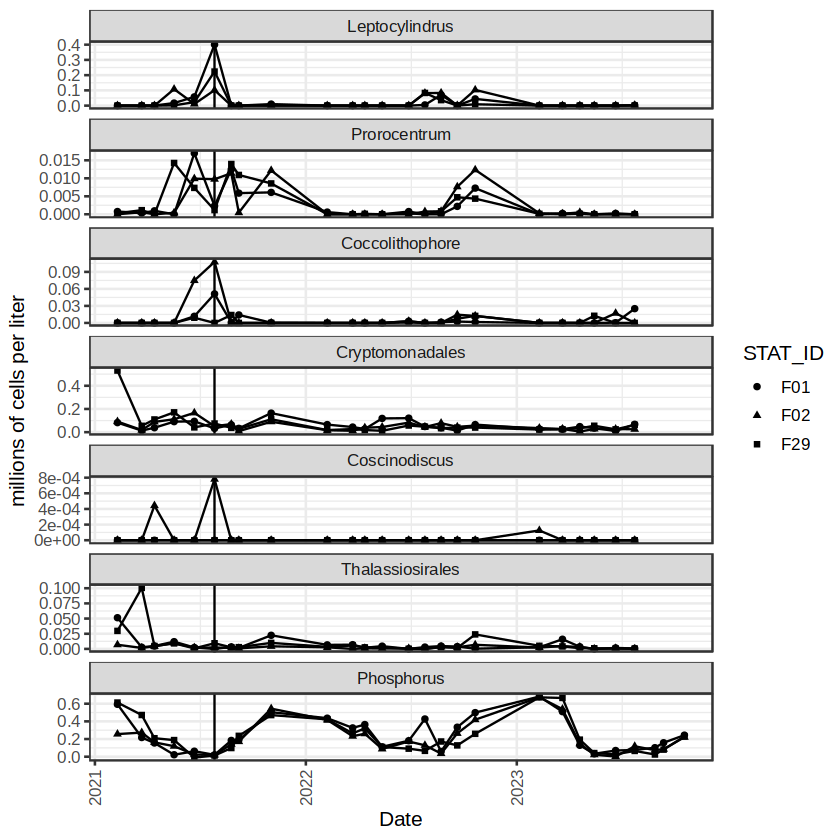

In [15]:
infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                  grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)|grepl("Coscino",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus")) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Cryptomonadales",
                                            "Coscinodiscus",
                                            "Thalassiosirales",
                                            "Prymesiophyte",
                                            "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y",ncol=1) +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
#ggsave("../figures/abundances_w_phosphate.pdf")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type, Date, and STAT_ID.
ℹ Output i

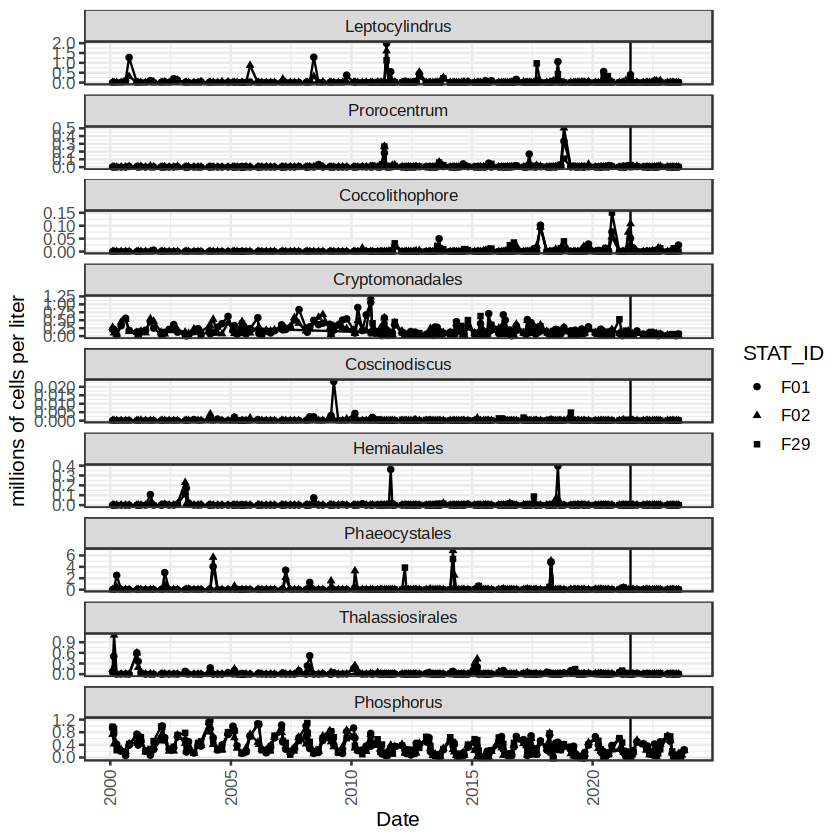

In [21]:
infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)|grepl("Hemiaulus",DESCR)|
                  grepl("Eucampia",DESCR)|grepl("Cerataulina",DESCR)|
                  grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)|
                  grepl("Phaeo",DESCR)|
                  grepl("Coscino",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Hemiaulus",DESCR)|grepl("Eucampia",DESCR)|
                                 grepl("Cerataulina",DESCR)~
                                 "Hemiaulales",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus",
                                 grepl("Phaeo",DESCR)~
                                 "Phaeocystales")) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    #dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Cryptomonadales",
                                            "Coscinodiscus",
                                            "Hemiaulales",
                                            "Phaeocystales",
                                            "Thalassiosirales",
                                            "Prymesiophyte",
                                            "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y",ncol=1) +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
#ggsave("../figures/abundances_w_phosphate.pdf")

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR,
  UNIT_CODE, and STAT_ID.
ℹ Output is grouped by Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, and
  UNIT_CODE.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Date, ORDERED_DEPTH_CODE, GROUP_ID, DESCR, UNIT_CODE,
  STAT_ID))` for per-operation grouping (`?dplyr::dplyr_by`) instead.
`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by type, Date, and STAT_ID.
ℹ Output i

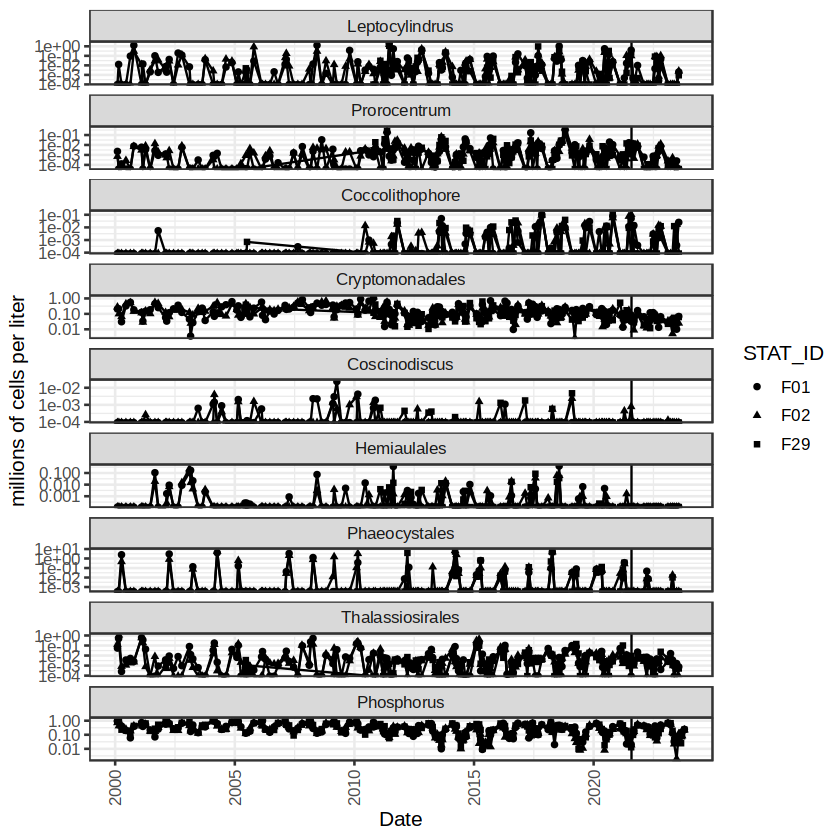

In [22]:
infill_dates_crypto = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES","CRYPTOPHYTES")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE,STAT_ID) %>% 
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date","STAT_ID"),names_from="DESCR",values_from="Group_Ct")

infill_dates_crypto[is.na(infill_dates_crypto)]=0

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")|
                               starts_with("STAT_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)|grepl("Hemiaulus",DESCR)|
                  grepl("Eucampia",DESCR)|grepl("Cerataulina",DESCR)|
                  grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)|
                  grepl("Phaeo",DESCR)|
                  grepl("Coscino",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales",
                                 grepl("Chrysoc",DESCR)|grepl("Prymnes",DESCR)~
                                 "Prymesiophyte",
                                 grepl("Hemiaulus",DESCR)|grepl("Eucampia",DESCR)|
                                 grepl("Cerataulina",DESCR)~
                                 "Hemiaulales",
                                 grepl("Coscino",DESCR)~
                                 "Coscinodiscus",
                                 grepl("Phaeo",DESCR)~
                                 "Phaeocystales")) %>%
    dplyr::group_by(type,Date,STAT_ID) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

infill_dates_tot = infill_dates_crypto  %>% 
    tidyr::pivot_longer(cols=!starts_with("Date")& !starts_with("STAT_ID"),
                        names_to = "organism", values_to="counts")  %>%
    dplyr::group_by(STAT_ID,Date) %>%
    dplyr::summarize(total_counts=sum(counts))

main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(infill_dates_tot) %>%
    dplyr::mutate(Scaled_Ct = Group_Ct) %>% # / total_counts) %>%
    dplyr::bind_rows(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("type"="Category","Scaled_Ct"="FFU_RESULT")))%>%
    #dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Cryptomonadales",
                                            "Coscinodiscus",
                                            "Hemiaulales",
                                            "Phaeocystales",
                                            "Thalassiosirales",
                                            "Prymesiophyte",
                                            "Phosphorus")))) + 
    geom_point(aes(x=Date,y=Scaled_Ct,shape=STAT_ID)) +  
    geom_line(aes(x=Date,y=Scaled_Ct,group=STAT_ID)) + 
    geom_vline(aes(xintercept=as.Date("2021-07-27",format="%Y-%m-%d"))) + 
    scale_y_log10()+
    theme_bw(base_size=12) + facet_wrap(~type,scales="free_y",ncol=1) +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter")
main_grp_trends
#ggsave("../figures/abundances_w_phosphate.pdf")

In [17]:
colnames(infill_dates_crypto)

[1] "Date"                                                                 
  [2] "STAT_ID"                                                              
  [3] "Centric diatom sp. group 1 diam <10 microns"                          
  [4] "Chaetoceros sp. group 1 diam <10 microns"                             
  [5] "Corethron criophilum"                                                 
  [6] "Guinardia delicatula"                                                 
  [7] "Rhizosolenia setigera"                                                
  [8] "Skeletonema costatum species complex"                                 
  [9] "Thalassiosira nordenskioeldii"                                        
 [10] "Thalassiosira sp. group 3 10-20 microns length"                       
 [11] "Cryptomonas sp. group 1 length <10 microns"                           
 [12] "Cryptomonas sp. group 2 length >10 microns"                           
 [13] "Gymnodinium sp. group 1 5-20 microns width, 10-20 microns length"     
 [14] "Gymnodinium sp. group 2 21-40 microns width, 21-50 microns length"    
 [15] "Gyrodinium spirale"                                                   
 [16] "Heterocapsa rotundata"                                                
 [17] "Prorocentrum micans"                                                  
 [18] "Protoperidinium bipes"                                                
 [19] "Cylindrotheca closterium"                                             
 [20] "Pennate diatom sp. group 2 10-30 microns length"                      
 [21] "Pennate diatom sp. group 3 31-60 microns length"                      
 [22] "Pleurosigma spp."                                                     
 [23] "Thalassionema nitzschioides"                                          
 [24] "Chaetoceros debilis"                                                  
 [25] "Chaetoceros sp. group 2 diam 10-30 microns"                           
 [26] "Leptocylindrus minimus"                                               
 [27] "Thalassiosira rotula"                                                 
 [28] "Chaetoceros didymus"                                                  
 [29] "Detonula confervacea"                                                 
 [30] "Thalassiosira anguste-lineata"                                        
 [31] "Thalassiosira sp. group 4 20-30 microns length"                       
 [32] "Gyrodinium sp. group 2 21-40 microns width, 21-50 microns length"     
 [33] "Prorocentrum minimum"                                                 
 [34] "Phaeocystis pouchetii"                                                
 [35] "Ceratium fusus"                                                       
 [36] "Ceratium lineatum"                                                    
 [37] "Ceratium longipes"                                                    
 [38] "Ceratium tripos"                                                      
 [39] "Dinophysis norvegica"                                                 
 [40] "Heterocapsa triquetra"                                                
 [41] "Bellerochea malleus"                                                  
 [42] "Dactyliosolen fragilissimus"                                          
 [43] "Leptocylindrus danicus"                                               
 [44] "Amphidinium spp."                                                     
 [45] "Scrippsiella trochoidea"                                              
 [46] "Guinardia flaccida"                                                   
 [47] "Ceratium macroceros"                                                  
 [48] "Pseudo-nitzschia pungens"                                             
 [49] "Chaetoceros contortus"                                                
 [50] "Chaetoceros decipiens"                                                
 [51] "Chaetoceros socialis"                                                 
 [52] "Ditylum brightwel

In [15]:
main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("phosphate"="FFU_RESULT")))%>%
    dplyr::filter((Date>as.Date("2020-12-01",format="%Y-%m-%d"))) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore"))) %>%
    dplyr::select(Date,phosphate,STAT_ID,type,Group_Ct) %>%
    dplyr::distinct() %>%
    tidyr::pivot_wider(id_cols = c("Date","phosphate","STAT_ID"),names_from="type",
                       values_from="Group_Ct") %>%
    dplyr::filter(STAT_ID=="F29"))+ 
    geom_point(aes(x=phosphate,y=Prorocentrum/max(Prorocentrum),
                   shape="Prorocentrales"),size=3,fill="black") +
    #geom_smooth(aes(x=phosphate,y=Coccolithophore/max(Coccolithophore)),
    #            method="lm")+
    geom_point(aes(x=phosphate,y=Coccolithophore/max(Coccolithophore),
                   shape="Coccolithophores"),size=3,fill="black") +  
    geom_point(aes(x=phosphate,y=Leptocylindrus/max(Leptocylindrus),
                   shape="Leptocylindrales"),size=3,fill="black") +    
    theme_bw(base_size=12) + #facet_wrap(~type,scales="free_y") +  
    #theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("fraction of maximum millions of cells per liter") + 
    xlab("Orthophosphate (uM)")+
    scale_shape_manual(values=c(25,23,21))
main_grp_trends

ggsave("../figures/orthophosphate_vs_counts.pdf")

Joining with `by = join_by(Date, STAT_ID)`
Warning message in dplyr::left_join(., processed_df %>% dplyr::filter(PARAM_CODE %in% :
“Detected an unexpected many-to-many relationship between `x` and `y`.
ℹ Row 1 of `x` matches multiple rows in `y`.
ℹ Row 57 of `y` matches multiple rows in `x`.
ℹ If a many-to-many relationship is expected, set `relationship =
  "many-to-many"` to silence this warning.”
Warning message:
“Values from `Group_Ct` are not uniquely identified; output will contain
list-cols.
• Use `values_fn = list` to suppress this warning.
• Use `values_fn = {summary_fun}` to summarise duplicates.
• Use the following dplyr code to identify duplicates.
  {data} |>
  dplyr::summarise(n = dplyr::n(), .by = c(Date, phosphate, STAT_ID, type)) |>
  dplyr::filter(n > 1L)”
ERROR while rich displaying an object: Error in `geom_point()`:
! Problem while computing aesthetics.
ℹ Error occurred in the 1st layer.
Caused by error in `max()`:
! invalid 'type' (list) of argument

Traceback:
1.

ERROR: [1m[33mError[39m in `geom_point()`:[22m
[1m[22m[33m![39m Problem while computing aesthetics.
[36mℹ[39m Error occurred in the 1st layer.
[1mCaused by error in `max()`:[22m
[33m![39m invalid 'type' (list) of argument


In [ ]:
main_grp_trends = ggplot(for_plotting %>% 
    dplyr::left_join(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("phosphate"="FFU_RESULT")))%>%
    dplyr::filter((Date>as.Date("2020-12-01",format="%Y-%m-%d"))) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore"))) %>%
    dplyr::select(Date,phosphate,STAT_ID,type,Group_Ct) %>%
    dplyr::distinct() %>%
    tidyr::pivot_wider(id_cols = c("Date","phosphate","STAT_ID"),names_from="type",
                       values_from="Group_Ct") %>%
    dplyr::filter(STAT_ID=="F29"))+ 
    geom_hist(aes(x=phosphate,y=Prorocentrum/max(Prorocentrum),
                   shape="Prorocentrales"),size=3,fill="black") + 
    geom_point(aes(x=phosphate,y=Coccolithophore/max(Coccolithophore),
                   shape="Coccolithophores"),size=3,fill="black") +  
    geom_point(aes(x=phosphate,y=Leptocylindrus/max(Leptocylindrus),
                   shape="Leptocylindrales"),size=3,fill="black") +    
    theme_bw(base_size=12) + #facet_wrap(~type,scales="free_y") +  
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) +
    ylab("millions of cells per liter") + 
    scale_shape_manual(values=c(25,23,21))
main_grp_trends

In [ ]:
## Spearman correlations of counts and metaT.

for_plotting = infill_dates_crypto %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::filter(grepl("Proro",DESCR)|grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)|
                  grepl("Leptocy",DESCR)|grepl("Thalassios",DESCR)|grepl("Cryptomonas",DESCR)|
                  grepl("Chilomonas",DESCR)|grepl("Hemiselmis",DESCR)) %>%
    dplyr::mutate(type=case_when(grepl("Coccolithophorid",DESCR)|grepl("Emiliania",DESCR)~"Coccolithophore",
                                 grepl("Prorocentru",DESCR)~"Prorocentrum",
                                 grepl("Leptocylin",DESCR)~"Leptocylindrus",
                                 grepl("Thalassiosir",DESCR)~"Thalassiosirales",
                                 grepl("Cryptomonas",DESCR)|grepl("Hemiselmis",DESCR)|
                                 grepl("Chilomonas",DESCR)~"Cryptomonadales")) %>%
    dplyr::group_by(type,Date) %>% dplyr::summarize(Group_Ct=sum(Group_Ct,na.rm=TRUE))

merged_for_test = for_plotting %>% 
    dplyr::left_join(processed_df %>% 
                     dplyr::filter(PARAM_CODE%in%c("PO4")) %>%
                     dplyr::rename(c("phosphate"="FFU_RESULT")))%>%
    dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore",
                                            "Thalassiosirales",
                                            "Cryptomonadales"))) %>%
    dplyr::select(Date,phosphate,STAT_ID,type,Group_Ct) %>%
    dplyr::distinct() %>%
    tidyr::pivot_wider(id_cols = c("Date","phosphate","STAT_ID"),names_from="type",
                       values_from="Group_Ct") %>% dplyr::filter(STAT_ID=="F29")

In [52]:
cor(merged_for_test$Coccolithophore, merged_for_test$phosphate, method = "spearman")

[1] -0.6467636

In [ ]:
for_plotting %>% 
    dplyr::left_join(processed_df %>% 
                     dplyr::filter(Category%in%c("Phosphorus")) %>%
                     dplyr::rename(c("phosphate"="FFU_RESULT")))%>%
    dplyr::filter(Date>as.Date("2020-12-01",format="%Y-%m-%d")) %>%
    dplyr::mutate(type=factor(type,levels=c("Leptocylindrus",
                                            "Prorocentrum",
                                            "Coccolithophore"))) 

`summarise()` has grouped output by 'Date', 'ORDERED_DEPTH_CODE', 'GROUP_ID',
'DESCR'. You can override using the `.groups` argument.
`summarise()` has grouped output by 'Date', 'ORDERED_DEPTH_CODE', 'GROUP_ID'.
You can override using the `.groups` argument.
`summarise()` has grouped output by 'regime', 'DESCR'. You can override using
the `.groups` argument.
`summarise()` has grouped output by 'regime', 'DESCR', 'GROUP_ID'. You can
override using the `.groups` argument.
Saving 7 x 7 in image


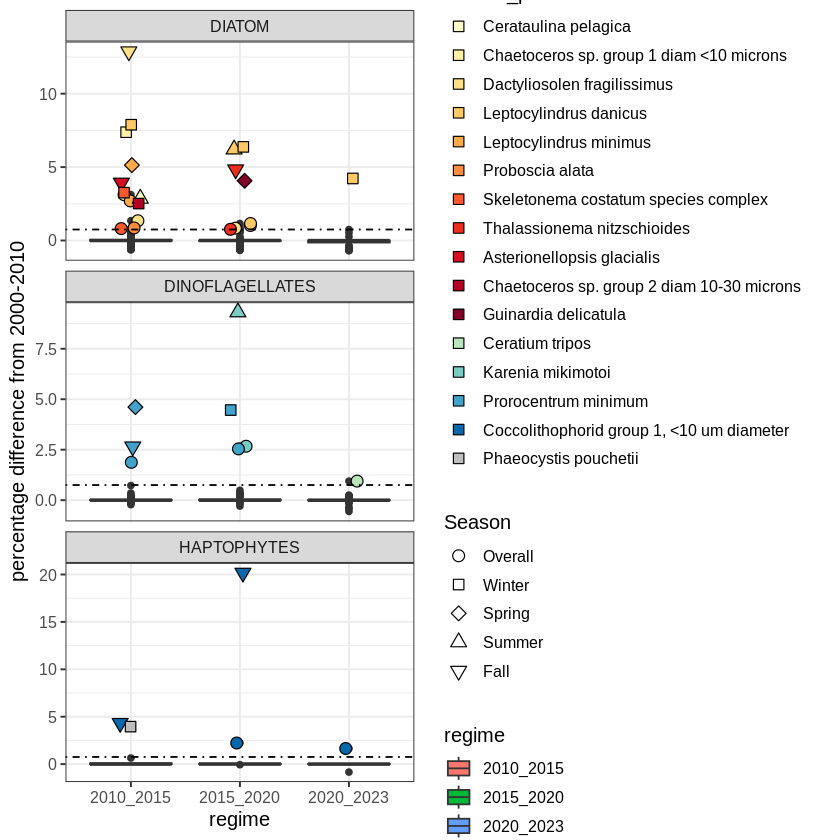

In [13]:
infill_dates = paired_data %>% 
    dplyr::filter((ORDERED_DEPTH_CODE=="A")&(METH_CODE=="COU_WW")) %>%
    dplyr::group_by(Date,ORDERED_DEPTH_CODE,GROUP_ID,DESCR,UNIT_CODE) %>% 
    dplyr::summarize(Group_Ct = sum(FFU_RESULT,na.rm=TRUE))%>%
    dplyr::filter(trimws(GROUP_ID)%in%c("HAPTOPHYTES","CENTRIC DIATOM",
                                        "PENNATE DIATOM","DINOFLAGELLATES")) %>%
    dplyr::summarize(Group_Ct = case_when(UNIT_CODE=="E6CELLS/L"~sum(Group_Ct,na.rm=TRUE),
                                          UNIT_CODE=="CELLS/L"~sum(Group_Ct,na.rm=TRUE)/10^6)) %>%
    tidyr::pivot_wider(id_cols=c("Date"),names_from="DESCR",values_from="Group_Ct")

infill_dates[is.na(infill_dates)]=0

group_connect = paired_data %>% dplyr::select(GROUP_ID,DESCR) %>%
    dplyr::mutate(DESCR=trimws(DESCR)) %>%
    dplyr::distinct() %>% dplyr::filter(!is.na(GROUP_ID) & !is.na(DESCR))

for_plotting = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::mutate(GROUP_ID = case_when(grepl("DIATOM",GROUP_ID)~"DIATOM",
                                      TRUE~GROUP_ID))%>%
    dplyr::mutate(Year = year(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                 Month = month(as.Date(Date,format='%d-%b-%Y %H:%M:%S'))) %>%
    dplyr::mutate(regime = case_when(Year > 2020 ~ "2020_2023",
                                     Year > 2015 ~ "2015_2020",
                                     Year > 2010 ~ "2010_2015",
                                    TRUE ~"early")) %>%
    dplyr::group_by(regime,DESCR,GROUP_ID) %>% dplyr::summarize(meanCt = mean(Group_Ct)) %>%
    tidyr::pivot_wider(id_cols=c("DESCR","GROUP_ID"),names_from="regime",
                       values_from="meanCt")%>%
    tidyr::pivot_longer(cols=!(starts_with("GROUP_ID")|starts_with("DESCR")|starts_with("early")),
                       names_to="regime",
                       values_to="value") %>%
    dplyr::mutate(labeled_pts = case_when(((value)-(early))/(early+0.01)> 0.75~DESCR,
                                          TRUE~NA)) %>%
    dplyr::mutate(Season="Overall")

for_plotting_by_season = infill_dates %>%
    tidyr::pivot_longer(cols=!(starts_with("Date")|starts_with("GROUP_ID")),
                        names_to="DESCR",values_to="Group_Ct") %>%
    dplyr::left_join(group_connect,by=c("DESCR")) %>%
    dplyr::mutate(GROUP_ID = case_when(grepl("DIATOM",GROUP_ID)~"DIATOM",
                                      TRUE~GROUP_ID))%>%
    dplyr::mutate(Year = year(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                 Month = month(as.Date(Date,format='%d-%b-%Y %H:%M:%S'))) %>%
    dplyr::mutate(regime = case_when(Year > 2020 ~ "2020_2023",
                                     Year > 2015 ~ "2015_2020",
                                     Year > 2010 ~ "2010_2015",
                                    TRUE ~"early")) %>%
    dplyr::mutate(Year = year(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                  Month = month(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                  Day = day(as.Date(Date,format='%d-%b-%Y %H:%M:%S')),
                  Date=as.Date(Date,format='%d-%b-%Y %H:%M:%S'),
                  Season = case_when((Month <= 3)&(Day<=21)~"Winter",
                                     (Month <=6) & (Day<=21)~"Spring",
                                     (Month <=9)&(Day<=21)~"Summer",
                                     (Month<=12)&(Day<=21)~"Fall",
                                     TRUE~"Winter")) %>%
    dplyr::group_by(regime,DESCR,GROUP_ID,Season) %>% 
    dplyr::summarize(meanCt = mean(Group_Ct)) %>%
    tidyr::pivot_wider(id_cols=c("DESCR","GROUP_ID","Season"),names_from="regime",
                       values_from="meanCt") %>%
    tidyr::pivot_longer(cols=!(starts_with("GROUP_ID")|starts_with("DESCR")|
                               starts_with("Season")|starts_with("early")),
                       names_to="regime",
                       values_to="value") %>%
    dplyr::mutate(labeled_pts = case_when(((value)-(early))/(early+0.01)> 2.5~DESCR,
                                          TRUE~NA))

redsPalette = colorRampPalette(brewer.pal(9, "YlOrRd"))

ggplot(for_plotting)+
    geom_boxplot(aes(x=regime,y=((value)-(early))/(early+0.01),group=paste0(GROUP_ID,regime),
                     fill=regime))+new_scale_fill() + 
    geom_jitter(data=for_plotting %>% dplyr::bind_rows(for_plotting_by_season) %>% 
               dplyr::filter(!is.na(labeled_pts))%>% 
               dplyr::mutate(labeled_pts=factor(labeled_pts,levels=(for_plotting %>% 
                                                dplyr::bind_rows(for_plotting_by_season) %>%
                                                dplyr::distinct(labeled_pts,.keep_all=TRUE) %>%
                                                dplyr::filter(!is.na(labeled_pts)) %>%
               dplyr::arrange(GROUP_ID))$labeled_pts)),
               aes(x=regime,y=((value)-(early))/(early+0.01),group=paste0(regime,GROUP_ID),
                   fill=labeled_pts,shape=Season), na.rm=TRUE,
               width=0.1,height=0,size=3)+
    guides(fill = guide_legend(override.aes = list(alpha = 1, shape = 22)))+
    scale_shape_manual(values=c(21,22,23,24,25),breaks=c("Overall","Winter","Spring","Summer","Fall")) +
    theme(axis.text.x = element_text(angle = 90, vjust = 0.5, hjust=1)) + 
    facet_wrap(~GROUP_ID,nrow=3,scales="free_y") + 
    geom_hline(aes(yintercept=0.75),linetype="dotdash") + theme_bw(base_size=12) + 
    ylab("percentage difference from 2000-2010")+ 
    scale_fill_manual(values=c(redsPalette(11),
                               brewer.pal(5,"GnBu")[2:5],"gray","white"))

ggsave("../figures/supplemental_seasonal_plot.pdf")